# Практична робота №22
## Часовий ряд: ковзне середнє, декомпозиція, тренд і прогноз

**Виконав:** Панасюк Дмитро  
**Номер за списком:** 15  
**Варіант:** №5 — **Дніпро**  
**Дані:** навчальний синтетичний ряд середньомісячних температур за 2015–2024 рр.

**Параметри варіанта:** середньорічна температура `base_temp = 10.0 °C`; сезонна амплітуда `amplitude = 14 °C`; закладений тренд `trend_per_year = 0.04 °C/рік`; стандартне відхилення шуму `noise_scale = 1.0 °C`; для відтворюваності `np.random.seed(5)`.

**Мета:** побудувати часовий ряд, дослідити згладжування, розкласти ряд на компоненти, отримати прогноз і перевірити, чи тренд статистично підтверджено.

## Завдання 1. Побудова багаторічного ряду

У кожному місяці використовується формула **температура = базовий рівень + лінійний тренд + річна сезонність + випадковий шум**. Частота часової шкали — початок кожного місяця (`MS`). Дані синтетичні, а не фактичні кліматичні спостереження.

Місто: Дніпро
Кількість спостережень: 120
Перші 12 місяців:
2015-01-01    -3.6
2015-02-01    -2.5
2015-03-01     5.4
2015-04-01     9.8
2015-05-01    17.1
2015-06-01    23.7
2015-07-01    23.1
2015-08-01    21.6
2015-09-01    17.2
2015-10-01     9.7
2015-11-01     1.8
2015-12-01    -2.3
Freq: MS

Діапазон: -4.9 ... 25.4 °C
Середня температура 2015 р.: 10.083 °C
Середня температура 2024 р.: 10.142 °C


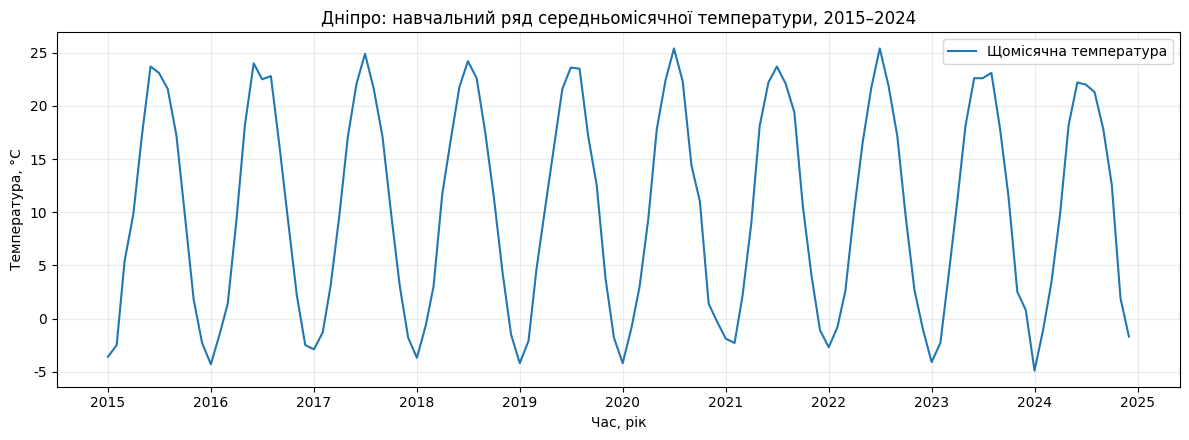

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress
from statsmodels.tsa.seasonal import seasonal_decompose

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

np.random.seed(5)
city = "Дніпро"
base_temp = 10.0
amplitude = 14.0
trend_per_year = 0.04
noise_scale = 1.0
n_years = 10

dates = pd.date_range(start="2015-01-01", periods=n_years * 12, freq="MS")
month = dates.month
years_elapsed = (dates.year - dates.year[0]) + (dates.month - 1) / 12
seasonal = amplitude * np.cos((month - 7) / 12 * 2 * np.pi)
trend = trend_per_year * years_elapsed
noise = np.random.normal(0, noise_scale, len(dates))
temp = np.round(base_temp + trend + seasonal + noise, 1)

climate_ts = pd.Series(temp, index=dates, name="температура")
print("Місто:", city)
print("Кількість спостережень:", len(climate_ts))
print("Перші 12 місяців:")
print(climate_ts.head(12).to_string())
print(f"\nДіапазон: {climate_ts.min():.1f} ... {climate_ts.max():.1f} °C")
print(f"Середня температура 2015 р.: {climate_ts.loc['2015'].mean():.3f} °C")
print(f"Середня температура 2024 р.: {climate_ts.loc['2024'].mean():.3f} °C")
assert len(climate_ts) == 120
assert isinstance(climate_ts.index, pd.DatetimeIndex)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(climate_ts.index, climate_ts.values, linewidth=1.5, label="Щомісячна температура")
ax.set_xlabel("Час, рік")
ax.set_ylabel("Температура, °C")
ax.set_title("Дніпро: навчальний ряд середньомісячної температури, 2015–2024")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

**Спостереження за графіком.** Щороку чітко видно сильний сезонний цикл: зимовий мінімум і літній максимум. Оскільки сезонна амплітуда становить ±14 °C, а задане потепління — лише 0,04 °C на рік (приблизно 0,4 °C за десятиліття), повільний тренд майже не розрізнити на тлі сезонних коливань і шуму. Середньорічне значення у 2015 р. дорівнює 10.083 °C, а у 2024 р. — 10.142 °C: проста різниця між крайніми роками зашумлена і не є надійним тестом тренду.

## Завдання 2. Ковзне середнє та лаг

Порівнюємо центровані вікна **3** і **12** місяців, а також трейлінгове вікно **12** місяців. `center=True` ставить усереднення поблизу середини відповідного вікна; без нього середнє розташоване на останньому місяці вікна.

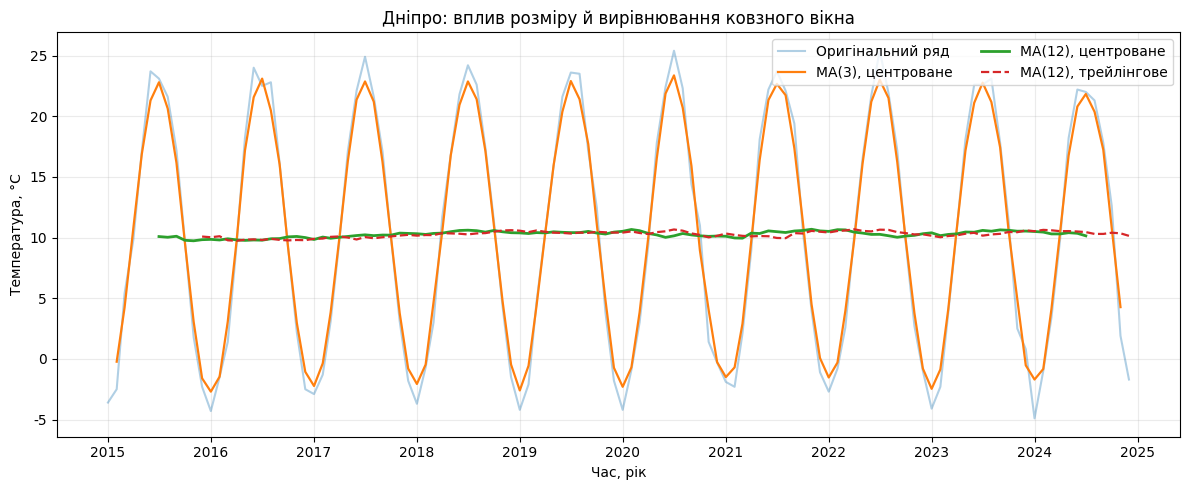

Перша доступна дата MA(12), центроване: 2015-07-01
Перша доступна дата MA(12), трейлінгове: 2015-12-01
Остання доступна дата MA(12), центроване: 2024-07-01
Остання доступна дата MA(12), трейлінгове: 2024-12-01


In [2]:
ma3_centered = climate_ts.rolling(window=3, center=True).mean()
ma12_centered = climate_ts.rolling(window=12, center=True).mean()
ma12_trailing = climate_ts.rolling(window=12).mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(climate_ts.index, climate_ts.values, alpha=0.35, label="Оригінальний ряд")
ax.plot(ma3_centered.index, ma3_centered.values, linewidth=1.6, label="MA(3), центроване")
ax.plot(ma12_centered.index, ma12_centered.values, linewidth=2.0, label="MA(12), центроване")
ax.plot(ma12_trailing.index, ma12_trailing.values, linewidth=1.6, linestyle="--", label="MA(12), трейлінгове")
ax.set_xlabel("Час, рік")
ax.set_ylabel("Температура, °C")
ax.set_title("Дніпро: вплив розміру й вирівнювання ковзного вікна")
ax.legend(loc="upper right", ncol=2)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
print("Перша доступна дата MA(12), центроване:", ma12_centered.first_valid_index().date())
print("Перша доступна дата MA(12), трейлінгове:", ma12_trailing.first_valid_index().date())
print("Остання доступна дата MA(12), центроване:", ma12_centered.last_valid_index().date())
print("Остання доступна дата MA(12), трейлінгове:", ma12_trailing.last_valid_index().date())

**Письмове пояснення.** Вікно **3 місяці** прибирає частину випадкового шуму, але лишає помітну сезонну хвилю. Вікно **12 місяців** охоплює повний річний цикл: позитивні літні та негативні зимові сезонні відхилення приблизно взаємно компенсуються, тож краще видно повільну зміну середнього рівня. Надто велике вікно також могло б згладити суттєві коротші зміни.

**Центрування і лаг.** Трейлінгове MA(12) використовує поточний і 11 попередніх місяців: його точка за грудень характеризує усереднений стан приблизно середини відповідного року, тобто відстає за часом приблизно на **5,5 місяця**. Центроване MA(12) розміщене поблизу середини вікна і краще підходить для опису історичного тренду; з парною довжиною вікна вирівнювання відбувається між двома центральними місяцями, а pandas ставить значення на один із місячних індексів. На початку й наприкінці ряду центроване середнє має `NaN`, бо не вистачає сусідніх спостережень. У реальному часі центроване середнє для останніх місяців отримати неможливо без майбутніх даних.

## Завдання 3. Декомпозиція ряду

Оскільки компоненти в даних додаються, обираємо **адитивну** декомпозицію з річним періодом `12`: `температура = trend + seasonal + resid`. Крайові пропуски в тренді та залишках є очікуваним наслідком згладжування.

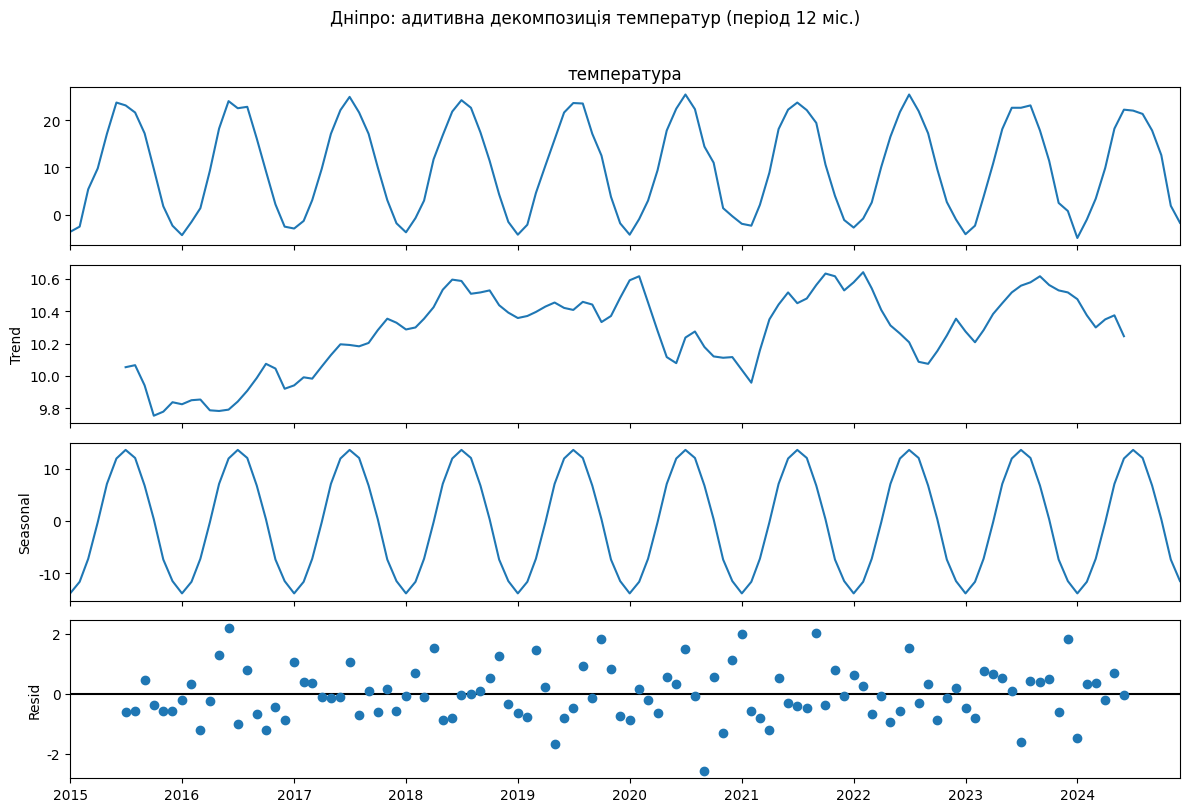

Сезонні ефекти за місяцями (°C):
1    -13.91
2    -11.68
3     -7.25
4     -0.25
5      7.13
6     12.00
7     13.66
8     12.11
9      6.80
10     0.33
11    -7.40
12   -11.55

Найтепліший місяць за сезонною складовою: 7
Найхолодніший місяць за сезонною складовою: 1
Розкид залишків std(ddof=1): 0.866 °C
Заданий рівень шуму: 1.000 °C
Оцінений тренд на першій доступній даті: 10.054 °C
Оцінений тренд на останній доступній даті: 10.246 °C


In [3]:
decomposition = seasonal_decompose(climate_ts, model="additive", period=12)

fig = decomposition.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Дніпро: адитивна декомпозиція температур (період 12 міс.)", y=1.01)
fig.tight_layout()
plt.show()

seasonal_by_month = decomposition.seasonal.groupby(decomposition.seasonal.index.month).mean()
warmest = int(seasonal_by_month.idxmax())
coldest = int(seasonal_by_month.idxmin())
resid_std = decomposition.resid.dropna().std()
print("Сезонні ефекти за місяцями (°C):")
print(seasonal_by_month.round(2).to_string())
print(f"\nНайтепліший місяць за сезонною складовою: {warmest}")
print(f"Найхолодніший місяць за сезонною складовою: {coldest}")
print(f"Розкид залишків std(ddof=1): {resid_std:.3f} °C")
print(f"Заданий рівень шуму: {noise_scale:.3f} °C")
print(f"Оцінений тренд на першій доступній даті: {decomposition.trend.dropna().iloc[0]:.3f} °C")
print(f"Оцінений тренд на останній доступній даті: {decomposition.trend.dropna().iloc[-1]:.3f} °C")

**Інтерпретація трьох компонентів:**

1. **Тренд:** після прибирання річного циклу коливається поблизу 10 °C і має дуже слабкий нахил угору, помітно нерівний через випадковий шум і згладжування. Його не слід сприймати як доказ потепління без статистичного тесту.
2. **Сезонність:** найбільший позитивний внесок припадає на **липень (місяць 7)**, найбільший негативний — на **січень (місяць 1)**. Це узгоджується з генерацією через косинус із максимумом у липні та амплітудою 14 °C.
3. **Залишок:** його стандартне відхилення становить **0.866 °C**, тобто той самий порядок величини, що закладений шум **1 °C**. Розбіжність закономірна: оцінювання тренду та сезонності поглинає частину випадкових відхилень, а вибірка скінченна.

## Завдання 4. Прогноз температури на 12 місяців уперед

Продовжуємо пряму, підібрану до **непорожніх** значень компоненти тренду, використовуючи *оригінальні* номери місяців 0…119 (без зміщення індексу). Потім додаємо оцінений сезонний ефект відповідних місяців 2025 р. Прогноз не містить випадкового шуму, тому його лінія виглядає гладкішою за спостереження.

Нахил лінії декомпонованого тренду: 0.0537 °C/рік
Прогноз на 2025 рік (°C):
2025-01-01    -3.37
2025-02-01    -1.13
2025-03-01     3.30
2025-04-01    10.31
2025-05-01    17.69
2025-06-01    22.57
2025-07-01    24.23
2025-08-01    22.69
2025-09-01    17.39
2025-10-01    10.92
2025-11-01     3.19
2025-12-01    -0.95
Freq: MS


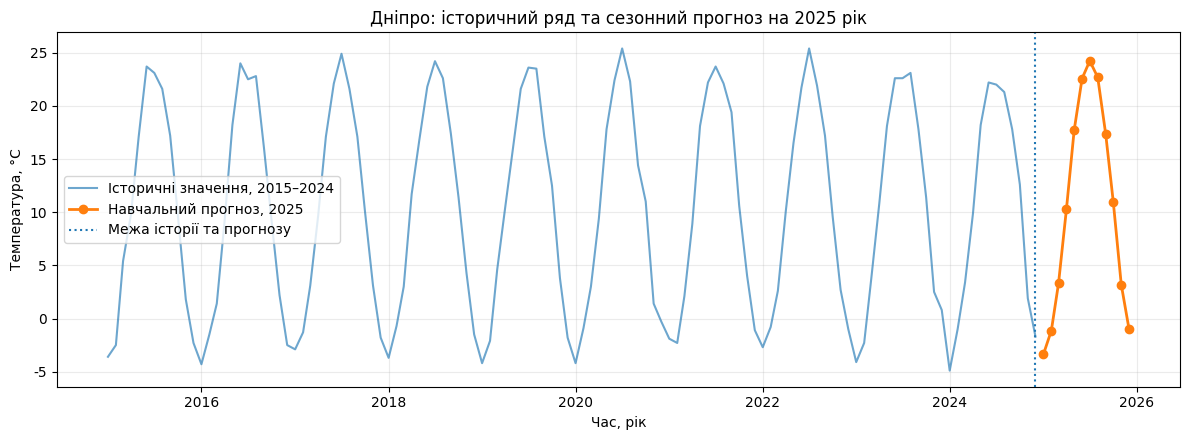

In [4]:
t = np.arange(len(climate_ts))
known = decomposition.trend.notna().values
fit = linregress(t[known], decomposition.trend[known].values)

n_ahead = 12
t_future = np.arange(len(climate_ts), len(climate_ts) + n_ahead)
future_dates = pd.date_range(climate_ts.index[-1] + pd.offsets.MonthBegin(1), periods=n_ahead, freq="MS")
trend_forecast = fit.intercept + fit.slope * t_future
seasonal_forecast = seasonal_by_month.reindex(future_dates.month).to_numpy()
forecast = pd.Series(trend_forecast + seasonal_forecast, index=future_dates, name="прогноз_°C")

print(f"Нахил лінії декомпонованого тренду: {fit.slope*12:.4f} °C/рік")
print("Прогноз на 2025 рік (°C):")
print(forecast.round(2).to_string())

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(climate_ts.index, climate_ts.values, label="Історичні значення, 2015–2024", alpha=0.65)
ax.plot(forecast.index, forecast.values, marker="o", linewidth=2, label="Навчальний прогноз, 2025")
ax.axvline(climate_ts.index[-1], linestyle=":", linewidth=1.5, label="Межа історії та прогнозу")
ax.set_xlabel("Час, рік")
ax.set_ylabel("Температура, °C")
ax.set_title("Дніпро: історичний ряд та сезонний прогноз на 2025 рік")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

**Письмове застереження.** Це **навчальний прогноз синтетичного ряду**, а не справжній прогноз погоди для Дніпра. Він механічно продовжує оцінений лінійний тренд (приблизно **0.0537 °C/рік**) і повторює середню річну сезонність. У реальному кліматі температура наступних місяців залежить також від циркуляції атмосфери, аномальних погодних явищ та інших чинників, яких тут немає. Через випадкові коливання фактичні значення можуть істотно відхилятися від наведених точок; зі збільшенням горизонту прогнозу невизначеність зростає. Високої точності або гарантованого потепління така екстраполяція не обіцяє.

## Завдання 5. Статистична перевірка тренду: 10 років проти 3 і 2 років

**Гіпотези:**

- **H₀:** істинний нахил тренду = 0 °C/рік (видима зміна може бути шумом).
- **H₁:** істинний нахил ≠ 0 °C/рік (двобічний тест).

На відміну від регресії на перекривних 12-місячних ковзних середніх, тут використовуємо **ряд без сезонної компоненти**; це не створює штучних повторних залежних усереднених точок. Рівень значущості `α = 0.05`; 95% інтервал приблизно за формулою `slope ± 1.96 × stderr`, як вимагає умова.

In [5]:
deseason = climate_ts - decomposition.seasonal
t_years = np.arange(len(climate_ts)) / 12
trend_test = linregress(t_years, deseason.values)
ci_lower = trend_test.slope - 1.96 * trend_test.stderr
ci_upper = trend_test.slope + 1.96 * trend_test.stderr

trend_3y = linregress(np.arange(36) / 12, deseason.values[-36:])
trend_2y = linregress(np.arange(24) / 12, deseason.values[-24:])
comparison = pd.DataFrame([
    {"Період": "10 років", "n": 120, "нахил_°C_рік": trend_test.slope,
     "stderr": trend_test.stderr, "p_value": trend_test.pvalue},
    {"Період": "3 останні роки", "n": 36, "нахил_°C_рік": trend_3y.slope,
     "stderr": trend_3y.stderr, "p_value": trend_3y.pvalue},
    {"Період": "2 останні роки", "n": 24, "нахил_°C_рік": trend_2y.slope,
     "stderr": trend_2y.stderr, "p_value": trend_2y.pvalue},
])
print(comparison.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print(f"\n95% ДІ для 10-річного нахилу: [{ci_lower:.4f}; {ci_upper:.4f}] °C/рік")
print("Висновок при α=0.05:", "відхиляємо H₀" if trend_test.pvalue < 0.05 else "не відхиляємо H₀")
assert np.isclose(trend_test.slope, comparison.loc[0, "нахил_°C_рік"])
assert (ci_lower <= 0 <= ci_upper) == (trend_test.pvalue >= 0.05)

        Період   n  нахил_°C_рік   stderr  p_value
      10 років 120      0.034337 0.029897 0.253087
3 останні роки  36     -0.023619 0.179975 0.896365
2 останні роки  24     -0.152324 0.364549 0.680113

95% ДІ для 10-річного нахилу: [-0.0243; 0.0929] °C/рік
Висновок при α=0.05: не відхиляємо H₀


**Оцінка на всіх 10 роках:** `slope = +0.0343 °C/рік`, `stderr = 0.0299`, `p-value = 0.2531`, приблизний **95% ДІ [-0.0243; +0.0929] °C/рік**. Оскільки `p > 0.05` і нуль входить у довірчий інтервал, **немає підстав відхиляти H₀**: статистично значуще потепління на цих 120 синтетичних значеннях **не підтверджене**, хоча в самій генерації задано позитивний тренд **+0,04 °C/рік**. Недостатня статистична потужність за такого слабкого сигналу не означає, що тренд дорівнює нулю.

**Коротше вікно:** на останніх 3 роках нахил дорівнює **-0.0236 °C/рік**, `p = 0.8964`; на останніх 2 роках — **-0.1523 °C/рік**, `p = 0.6801`. Знак навіть стає від'ємним, хоча в дані закладено потепління. Така нестійкість коротких оцінок і більші стандартні похибки демонструють, що окремі аномальні місяці можуть замаскувати слабкий багаторічний тренд.

**Методичне обмеження:** навіть після видалення сезонності часовий ряд може мати автокореляцію, а сама сезонна компонента оцінена з тих самих даних. Тому p-value звичайного `linregress` тут є навчальним наближенням, а не повною кліматологічною перевіркою. Для реальних вимірювань варто дослідити автокореляцію та використати модель з відповідними похибками.

## Відповіді на контрольні питання

**1. Чому часовий ряд не можна аналізувати як незалежну вибірку?**  
Сусідні місяці пов'язані в часі: є річна сезонність, плавні зміни тренду та можлива автокореляція помилок. Через це припущення про незалежні однаково розподілені спостереження порушується, а стандартні похибки й p-value наївних тестів можуть бути невірними. Спочатку слід врахувати часову структуру даних.

**2. Чому надто мале й надто велике вікно ковзного середнього — проблема?**  
Вікно 3 місяці майже не прибирає річну хвилю, тому сезонні піки приховують слабкий тренд. Натомість надмірне вікно може згладити важливі реальні короткочасні зміни, залишає менше доступних точок біля країв і для трейлінгового варіанта збільшує лаг. Для річної сезонності природний початковий вибір — 12 місяців або інший розмір, узгоджений із періодом циклу.

**3. Різниця між трейлінговим і центрованим середнім; чому друге недоступне онлайн?**  
Трейлінгове середнє за поточний місяць використовує тільки поточний і попередні місяці, тому його можна розрахувати відразу, але воно зміщує повільні зміни в часі. Центроване охоплює місяці до та після центральної дати, краще вирівнюючи середнє з історичним періодом. Для оцінки останньої дати в центрованому вікні потрібні значення кількох **майбутніх** місяців, яких іще немає.

**4. Чому p-value важливіше за сам знак нахилу?**  
Додатний нахил може випадково виникнути навіть тоді, коли істинний нахил дорівнює нулю. p-value оцінює, наскільки незвичним є такий або сильніший результат за H₀ і прийнятих припущень моделі; довірчий інтервал показує невизначеність оцінки. Для Дніпра оцінений нахил додатний, але `p ≈ 0.253` і 95% інтервал охоплює нуль, тож статистично підтвердженого тренду немає.

## Висновок

Для **Дніпра (варіант №5)** побудовано 120-місячний синтетичний ряд за 2015–2024 роки. Досліджено центровані й трейлінгові ковзні середні, проведено адитивну декомпозицію, побудовано сезонний прогноз на 2025 рік та перевірено значущість тренду на 10-, 3- і 2-річних вікнах. Виявлено сильну сезонність; при заданому слабкому довгостроковому тренді статистична перевірка **не дає підстав відхилити нульову гіпотезу** на рівні 5%. Прогноз є демонстраційним і не замінює прогноз на реальних даних.